<a href="https://colab.research.google.com/github/FridaOyucho/HTS-Model-/blob/main/xGBoostModelreviewed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install --upgrade pandas numpy scikit-learn xgboost

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, roc_auc_score,classification_report
from xgboost import XGBClassifier
import pickle
from sklearn.metrics import average_precision_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import recall_score
from sklearn.metrics import precision_score
from sklearn.metrics import f1_score

In [6]:
import os

print(os.path.getsize("sparse_dict.pkl"))

735277681


In [7]:
#Load the sparse dataset
import pickle
with open("sparse_dict.pkl", "rb") as f:
  sparse = pickle.load(f)


In [8]:
print(sparse.keys())

dict_keys(['sparse_train', 'sparse_val', 'sparse_test'])


In [9]:
for name, hts in sparse.items():
  print(name, hts.shape)

sparse_train (1271440, 56)
sparse_val (423814, 56)
sparse_test (423814, 56)


In [10]:
cols_to_drop = ["EMR", "SDP", "County","PatientPk","MFL_Code","SiteCode","Latitude","Longitude","Facility_Name", "SubCounty",
                "ClientTestedAs","CoupleDiscordant","VisitDate","NumberOfPartners"]

for key in sparse.keys():
  sparse[key] = sparse[key].drop(columns=cols_to_drop, errors="ignore")


In [11]:
#Check dtypes
for name, df in sparse.items():
    print(f"\n{name}")
    print(df.dtypes.value_counts())



sparse_train
object     41
float64     1
Name: count, dtype: int64

sparse_val
object     41
float64     1
Name: count, dtype: int64

sparse_test
object     41
float64     1
Name: count, dtype: int64


Prepare train, validation and test sets

In [12]:
#define features and target variable
X_train = sparse["sparse_train"].drop(columns=["FinalTestResult"])
y_train = sparse["sparse_train"]["FinalTestResult"]

X_val = sparse["sparse_val"].drop(columns=["FinalTestResult"])
y_val = sparse["sparse_val"]["FinalTestResult"]

X_test = sparse["sparse_test"].drop(columns=["FinalTestResult"])
y_test = sparse["sparse_test"]["FinalTestResult"]

Encode categorical variables

In [13]:
dtype_summary = pd.DataFrame({
    "Variable": X_train.columns,
    "Datatype": X_train.dtypes.astype(str)
})

dtype_summary = dtype_summary.sort_values("Datatype")

dtype_summary.head(100)

,Variable,Datatype
Age,Age,float64
PopulationType,PopulationType,object
KeyPopulation,KeyPopulation,object
PriorityPopulation,PriorityPopulation,object
IsHealthWorker,IsHealthWorker,object
TestedHIVBefore,TestedHIVBefore,object
ResultOfHIV,ResultOfHIV,object
EverHadSex,EverHadSex,object
SexuallyActive,SexuallyActive,object
NewPartner,NewPartner,object


In [14]:
for col in X_train.columns:
    print(col, X_train[col].nunique())


PopulationType 3
KeyPopulation 5
PriorityPopulation 1
IsHealthWorker 3
TestedHIVBefore 2
ResultOfHIV 2
EverHadSex 3
SexuallyActive 5
NewPartner 4
PartnerHIVStatus 5
MultiplePartners 3
AlcoholSex 5
MoneySex 4
CondomBurst 4
UnknownStatusPartner 4
KnownStatusPartner 4
Pregnant 4
BreastfeedingMother 4
ExperiencedViolenceScreening 4
CurrentlyOnPrep 3
TraditionalProcedures 2
MothersStatus 4
ResultOfHIVSelf 2
ScreenedTB 3
TBStatus 4
ReceivedServices 9
ViolenceScreeningType 9
Sex 2
MaritalStatus 7
PatientDisabled 2
EverTestedForHiv 2
MonthsSinceLastTest 5
PriorityPopulationType 5
Age 99
GBVSexual 3
GBVPhysical 3
GBVEmotional 3
ReceivedPREP 2
ReceivedTB 2
ReceivedSTI 2
dayofweek 7


In [15]:
# One-hot encode categorical features into sparse matrices
from scipy import sparse as scipy_sparse
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_cols = X_train.select_dtypes(
    include=["object", "category", "str"]
).columns

encoder = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore", dtype=np.float32), categorical_cols)
    ],
    remainder="passthrough",
    sparse_threshold=1.0,
)

X_train_enc = scipy_sparse.csr_matrix(encoder.fit_transform(X_train))
X_val_enc = scipy_sparse.csr_matrix(encoder.transform(X_val))
X_test_enc = scipy_sparse.csr_matrix(encoder.transform(X_test))
encoded_feature_names = encoder.get_feature_names_out()

In [16]:
# Verify that all splits have the same encoded features
print(X_train_enc.shape[1] == X_val_enc.shape[1])
print(X_train_enc.shape[1] == X_test_enc.shape[1])

True
True


In [17]:
# Preview a small dense slice without expanding the full sparse matrix
pd.DataFrame(
    X_train_enc[:5, :10].toarray(),
    columns=encoded_feature_names[:10],
)

,categorical__PopulationType_GP,categorical__PopulationType_KP,categorical__PopulationType_PRIORITY,categorical__KeyPopulation_FSW,categorical__KeyPopulation_MSM,categorical__KeyPopulation_NR,categorical__KeyPopulation_PRISONER,categorical__KeyPopulation_PWID,categorical__KeyPopulation_nan,categorical__PriorityPopulation_NR
0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
1,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
2,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
3,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


In [18]:
print("shape:", X_train_enc.shape)
print("dtype:", X_train_enc.dtype)
print("stored nonzeros:", X_train_enc.nnz)

shape: (1271440, 183)
dtype: float64
stored nonzeros: 52129040


In [19]:
density = X_train_enc.nnz / (X_train_enc.shape[0] * X_train_enc.shape[1])
print(f"Sparse matrix density: {density:.6f}")

Sparse matrix density: 0.224044


Encode target variable

In [20]:
#Check the output, if not in numericals, encode it
print(y_train.value_counts())

FinalTestResult
NEGATIVE    1239327
POSITIVE      32113
Name: count, dtype: int64


In [21]:
# Encode target labels using the training-set mapping
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
y_train_enc = label_encoder.fit_transform(y_train)
y_val_enc = label_encoder.transform(y_val)
y_test_enc = label_encoder.transform(y_test)

In [22]:
#Calculate this if positivity is much fewer than negatives: This is because HIV positivity is usually imbalanced
neg = (y_train_enc == 0).sum()
pos = (y_train_enc == 1).sum()

scale_pos_weight = neg / pos

print(scale_pos_weight)

38.592688319372215


Train XGBoost

In [23]:
# CHANGED: Define the hyperparameter grid and retain the best model/results.
from itertools import product
import time
import pandas as pd

max_depths = [5, 7]
learning_rates = [0.05, 0.1]
scale_pos_weights = [1, 10]
subsamples = [0.8, 1.0]

# CHANGED: Store every validation score instead of only overwriting xgb_model.
results = []
best_model = None
best_score = float("-inf")
best_params = None

# CHANGED: Track progress and estimate the remaining runtime.
configurations = list(product(
    max_depths,
    learning_rates,
    scale_pos_weights,
    subsamples
))
total_runs = len(configurations)
search_start = time.perf_counter()

for run_number, (max_depth, learning_rate, scale_pos_weight, subsample) in enumerate(
    configurations, start=1
):
    print(
        f"Starting {run_number}/{total_runs} ({run_number / total_runs:.1%}): "
        f"depth={max_depth}, lr={learning_rate}, spw={scale_pos_weight}, "
        f"subsample={subsample}",
        flush=True,
    )

    xgb_model = XGBClassifier(
        n_estimators=1000,
        max_depth=max_depth,
        learning_rate=learning_rate,
        scale_pos_weight=scale_pos_weight,
        subsample=subsample,
        random_state=2231,
        eval_metric="aucpr",
        early_stopping_rounds=50,
        n_jobs=-1
    )

    xgb_model.fit(
        X_train_enc,
        y_train_enc,
        eval_set=[(X_val_enc, y_val_enc)],
        verbose=False
    )

    score = xgb_model.best_score
    params = {
        "max_depth": max_depth,
        "learning_rate": learning_rate,
        "scale_pos_weight": scale_pos_weight,
        "subsample": subsample,
    }
    results.append({
        **params,
        "validation_aucpr": score,
        "best_iteration": xgb_model.best_iteration,
    })

    # CHANGED: Select the model using validation AUPRC, matching eval_metric.
    if score > best_score:
        best_score = score
        best_model = xgb_model
        best_params = params

    elapsed = time.perf_counter() - search_start
    average_time = elapsed / run_number
    eta_seconds = average_time * (total_runs - run_number)
    print(
        f"Completed {run_number}/{total_runs}; "
        f"AUPRC={score:.5f}; "
        f"elapsed={elapsed / 60:.1f} min; "
        f"ETA={eta_seconds / 60:.1f} min",
        flush=True,
    )

results_df = (
    pd.DataFrame(results)
    .sort_values("validation_aucpr", ascending=False)
    .reset_index(drop=True)
)

results_df.to_csv("xgb_hyperparameter_results.csv", index=False)

expected_runs = len(configurations)
print(f"Completed {len(results)} of {expected_runs} configurations")
print("Best parameters:", best_params)
print("Best validation AUPRC:", best_score)
print("Best iteration:", best_model.best_iteration)
results_df.head(10)

Starting 1/16 (6.2%): depth=5, lr=0.05, spw=1, subsample=0.8
Completed 1/16; AUPRC=0.21757; elapsed=49.0 min; ETA=735.2 min
Starting 2/16 (12.5%): depth=5, lr=0.05, spw=1, subsample=1.0
Completed 2/16; AUPRC=0.21520; elapsed=99.7 min; ETA=698.2 min
Starting 3/16 (18.8%): depth=5, lr=0.05, spw=10, subsample=0.8
Completed 3/16; AUPRC=0.21348; elapsed=146.5 min; ETA=634.9 min
Starting 4/16 (25.0%): depth=5, lr=0.05, spw=10, subsample=1.0
Completed 4/16; AUPRC=0.21230; elapsed=193.5 min; ETA=580.4 min
Starting 5/16 (31.2%): depth=5, lr=0.1, spw=1, subsample=0.8
Completed 5/16; AUPRC=0.21684; elapsed=230.9 min; ETA=508.0 min
Starting 6/16 (37.5%): depth=5, lr=0.1, spw=1, subsample=1.0
Completed 6/16; AUPRC=0.21535; elapsed=262.4 min; ETA=437.4 min
Starting 7/16 (43.8%): depth=5, lr=0.1, spw=10, subsample=0.8
Completed 7/16; AUPRC=0.21269; elapsed=292.1 min; ETA=375.5 min
Starting 8/16 (50.0%): depth=5, lr=0.1, spw=10, subsample=1.0
Completed 8/16; AUPRC=0.21328; elapsed=327.4 min; ETA=327.4

,max_depth,learning_rate,scale_pos_weight,subsample,validation_aucpr,best_iteration
0,7,0.05,1,0.8,0.218818,630
1,5,0.05,1,0.8,0.217567,999
2,5,0.10,1,0.8,0.216843,743
3,7,0.10,1,0.8,0.216587,319
4,7,0.05,1,1.0,0.216514,742
5,5,0.10,1,1.0,0.215348,619
6,5,0.05,1,1.0,0.215203,993
7,7,0.05,10,0.8,0.214521,575
8,7,0.10,1,1.0,0.214366,346
9,5,0.05,10,0.8,0.213482,930


In [25]:
import joblib
from google.colab import files

# Save models
joblib.dump(xgb_model, '/content/xgb_model.pkl')
joblib.dump(best_model, '/content/best_model.pkl')

# Download models
files.download('/content/xgb_model.pkl')
files.download('/content/best_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
from sklearn.metrics import precision_score, recall_score, classification_report

# Predictions on the test set
y_pred = best_model.predict(X_val_enc)

precision = precision_score(y_val_enc, y_pred)
recall = recall_score(y_val_enc, y_pred)

print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")

Precision: 0.6190
Recall: 0.0505


In [27]:
from sklearn.metrics import precision_score, recall_score, classification_report

# Predictions on the test set
y_pred = best_model.predict(X_test_enc)

precision = precision_score(y_test_enc, y_pred)
recall = recall_score(y_test_enc, y_pred)

print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")

Precision: 0.5962
Recall: 0.0466


Checking the maximum threshhold at maximum precision at 90%  and 95% sensitivity

In [35]:
from sklearn.metrics import precision_recall_curve

y_scores = best_model.predict_proba(X_test_enc)[:, 1]

precision, recall, thresholds = precision_recall_curve(y_test_enc, y_scores)

for target in [0.90, 0.95]:

    valid = np.where(recalls >= target)[0]

    if len(valid) == 0:
        print(f"No threshold achieves {target:.0%} sensitivity")
        continue

    idx = valid[-1]

    print(f"\nTarget sensitivity: {target:.0%}")
    print(f"Actual sensitivity: {recall[idx]:.4f}")
    print(f"Precision: {precision[idx]:.4f}")

    if idx < len(thresholds):
        print(f"Threshold: {thresholds[idx]:.6f}")


Target sensitivity: 90%
Actual sensitivity: 0.9010
Precision: 0.0489
Threshold: 0.011422

Target sensitivity: 95%
Actual sensitivity: 0.9512
Precision: 0.0402
Threshold: 0.006835


Validate the model at 90%

In [57]:
print("Validation shape:", X_val_enc.shape)
print("Validation positives:", y_val_enc.sum())
print("Validation total:", len(y_val_enc))

Validation shape: (423814, 183)
Validation positives: 10704
Validation total: 423814


In [59]:
from sklearn.metrics import precision_recall_curve

# Predicted probabilities on validation set
y_val_prob = best_model.predict_proba(X_val_enc)[:, 1]

# PR curve on validation set
precisions, recalls, thresholds = precision_recall_curve(
    y_val_enc,
    y_val_prob
)

# Find threshold closest to 90% recall
idx_90 = np.argmin(np.abs(recalls - 0.90))

print("Recall:", recalls[idx_90])
print("Precision:", precisions[idx_90])
print("Threshold:", thresholds[min(idx_90, len(thresholds)-1)])


Recall: 0.9000373692077728
Precision: 0.0513197496337728
Threshold: 0.012327581


In [60]:
threshold_val_90 = thresholds[min(idx_90, len(thresholds)-1)]

y_pred_val_90 = (
    y_val_prob >= threshold_val_90
).astype(int)

print(classification_report(
    y_val_enc,
    y_pred_val_90,
    digits=4
))

              precision    recall  f1-score   support

           0     0.9955    0.5689    0.7240    413110
           1     0.0513    0.9000    0.0971     10704

    accuracy                         0.5773    423814
   macro avg     0.5234    0.7345    0.4106    423814
weighted avg     0.9716    0.5773    0.7082    423814



In [ ]:
# Metrics
precision_val = precision_score(y_val_enc, y_pred_val_90)
recall_val = recall_score(y_val_enc, y_pred_val_90)

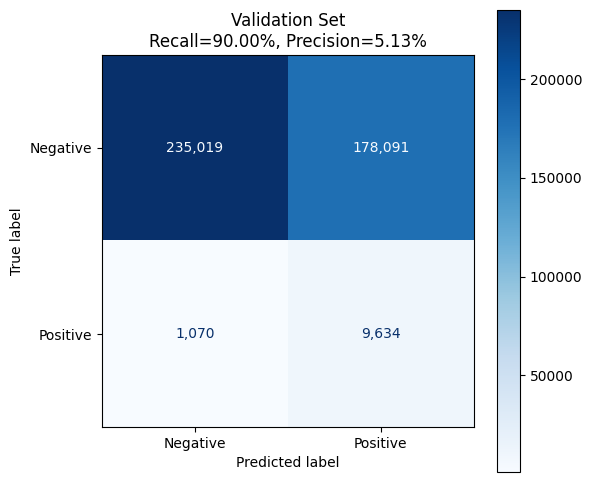

TN: 235,019
FP: 178,091
FN: 1,070
TP: 9,634


In [65]:
# Confusion matrix
cm = confusion_matrix(y_val_enc, y_pred_val_90)

fig, ax = plt.subplots(figsize=(6,6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot(
    cmap="Blues",
    ax=ax,
    values_format=",d"
)

plt.title(
    f"Validation Set\nRecall={recall_val:.2%}, Precision={precision_val:.2%}"
)

plt.show()

tn, fp, fn, tp = cm.ravel()

print(f"TN: {tn:,}")
print(f"FP: {fp:,}")
print(f"FN: {fn:,}")
print(f"TP: {tp:,}")

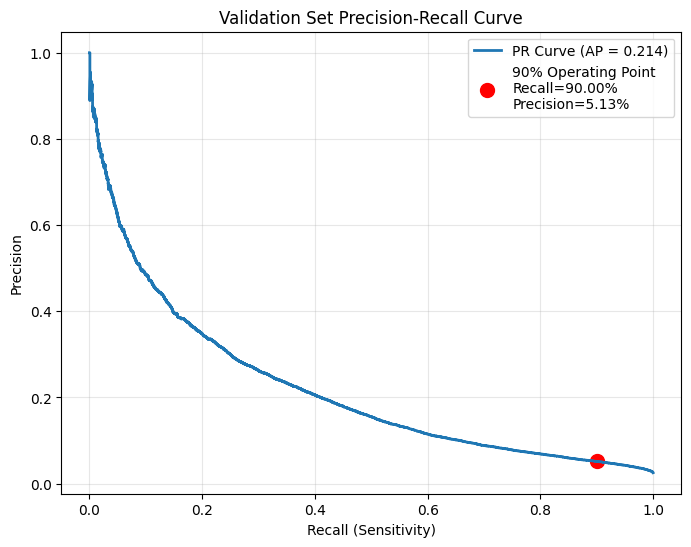

In [66]:
from sklearn.metrics import precision_score, recall_score

precision_90 = precision_score(y_val_enc, y_pred_val_90)
recall_90 = recall_score(y_val_enc, y_pred_val_90)

plt.figure(figsize=(8,6))

plt.plot(
    recalls,
    precisions,
    linewidth=2,
    label=f"PR Curve (AP = {ap:.3f})"
)

plt.scatter(
    recall_90,
    precision_90,
    color="red",
    s=100,
    label=f"90% Operating Point\nRecall={recall_90:.2%}\nPrecision={precision_90:.2%}"
)

plt.xlabel("Recall (Sensitivity)")
plt.ylabel("Precision")
plt.title("Validation Set Precision-Recall Curve")
plt.grid(True, alpha=0.3)
plt.legend()

plt.show()

Validate the model at 95%

In [67]:
threshold_95 = operating_points[0.95]["threshold"]

y_val_prob = best_model.predict_proba(X_val_enc)[:, 1]

y_pred_val_95 = (y_val_prob >= threshold_95).astype(int)

In [68]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_val_enc,
        y_pred_val_95,
        digits=4
    )
)

              precision    recall  f1-score   support

           0     0.9973    0.4191    0.5902    413110
           1     0.0409    0.9565    0.0785     10704

    accuracy                         0.4326    423814
   macro avg     0.5191    0.6878    0.3343    423814
weighted avg     0.9732    0.4326    0.5772    423814



In [69]:
precision_95 = precision_score(y_val_enc, y_pred_val_95)
recall_95 = recall_score(y_val_enc, y_pred_val_95)


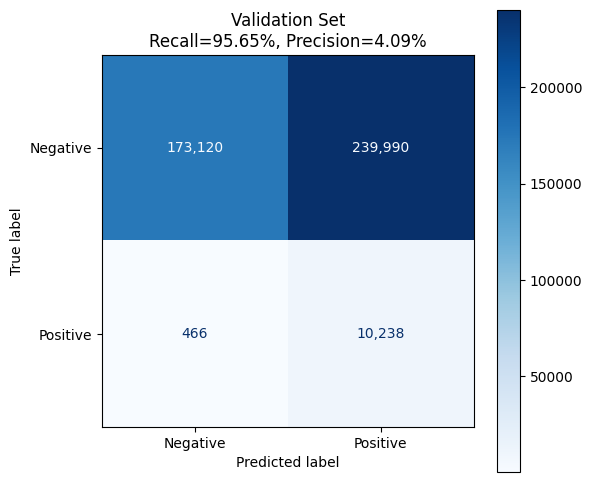

TN: 173,120
FP: 239,990
FN: 466
TP: 10,238


In [70]:
cm = confusion_matrix(y_val_enc, y_pred_val_95)

fig, ax = plt.subplots(figsize=(6,6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot(
    cmap="Blues",
    ax=ax,
    values_format=",d"
)

plt.title(
    f"Validation Set\nRecall={recall_95:.2%}, Precision={precision_95:.2%}"
)

plt.show()

tn, fp, fn, tp = cm.ravel()

print(f"TN: {tn:,}")
print(f"FP: {fp:,}")
print(f"FN: {fn:,}")
print(f"TP: {tp:,}")

Test the model at 90% sensitivity

In [48]:
threshold_90 = operating_points[0.90]['threshold']

print(operating_points[0.90])

y_pred_90 = (
    best_model.predict_proba(X_test_enc)[:,1]
    >= threshold_90
).astype(int)

print(classification_report(
    y_test_enc,
    y_pred_90,
    digits=4
))

{'idx': np.int64(159920), 'threshold': np.float32(0.011546714), 'recall': np.float64(0.9000373692077728), 'precision': np.float64(0.04913200465106791)}
              precision    recall  f1-score   support

           0     0.9953    0.5487    0.7074    413110
           1     0.0491    0.9000    0.0932     10704

    accuracy                         0.5575    423814
   macro avg     0.5222    0.7244    0.4003    423814
weighted avg     0.9714    0.5575    0.6919    423814



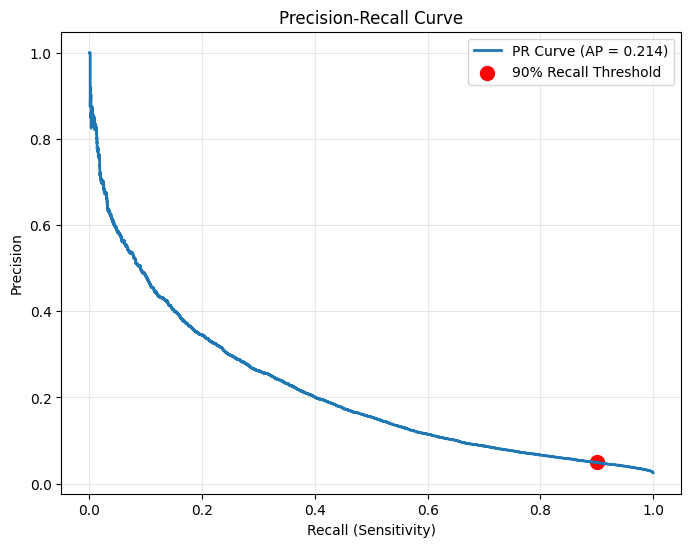

In [49]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score

# Probabilities
y_prob = best_model.predict_proba(X_test_enc)[:, 1]

# PR curve
precisions, recalls, thresholds = precision_recall_curve(
    y_test_enc,
    y_prob
)

ap = average_precision_score(y_test_enc, y_prob)

plt.figure(figsize=(8, 6))
plt.plot(recalls, precisions, linewidth=2,
         label=f'PR Curve (AP = {ap:.3f})')

# Mark the 90% recall operating point
plt.scatter(
    0.90,
    0.0491,
    color='red',
    s=100,
    label='90% Recall Threshold'
)

plt.xlabel("Recall (Sensitivity)")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

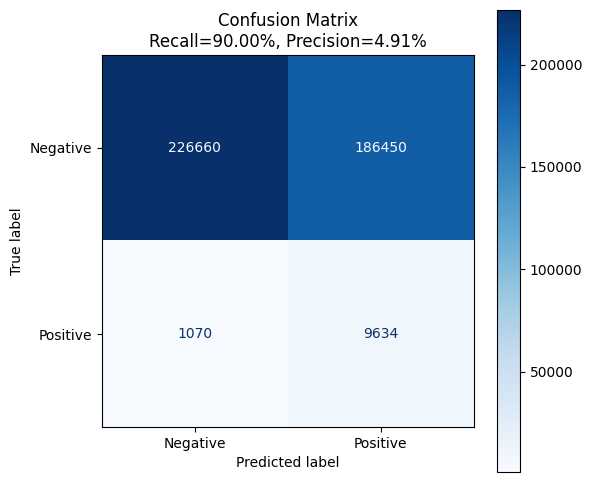

In [50]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test_enc, y_pred_90)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap="Blues", ax=ax)

plt.title(
    f"Confusion Matrix\nRecall={0.90:.2%}, Precision={0.0491:.2%}"
)
plt.show()

Test the model at 95% sensitivity

In [42]:
threshold_95 = thresholds[idx]

y_pred_95 = (
    best_model.predict_proba(X_test_enc)[:,1]
    >= threshold_95
).astype(int)

print(classification_report(
    y_test_enc,
    y_pred_95,
    digits=4
))

              precision    recall  f1-score   support

           0     0.9969    0.4113    0.5823    413110
           1     0.0402    0.9512    0.0771     10704

    accuracy                         0.4249    423814
   macro avg     0.5186    0.6813    0.3297    423814
weighted avg     0.9728    0.4249    0.5696    423814



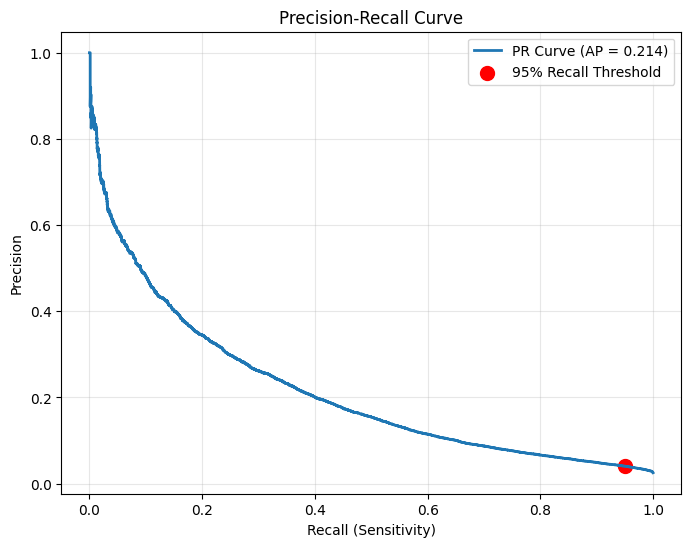

In [56]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score

# Probabilities
y_prob = best_model.predict_proba(X_test_enc)[:, 1]

# PR curve
precisions, recalls, thresholds = precision_recall_curve(
    y_test_enc,
    y_prob
)

ap = average_precision_score(y_test_enc, y_prob)

plt.figure(figsize=(8, 6))
plt.plot(recalls, precisions, linewidth=2,
         label=f'PR Curve (AP = {ap:.3f})')

# Mark the 95% recall operating point
plt.scatter(
    0.95,
    0.0402,
    color='red',
    s=100,
    label='95% Recall Threshold'
)

plt.xlabel("Recall (Sensitivity)")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

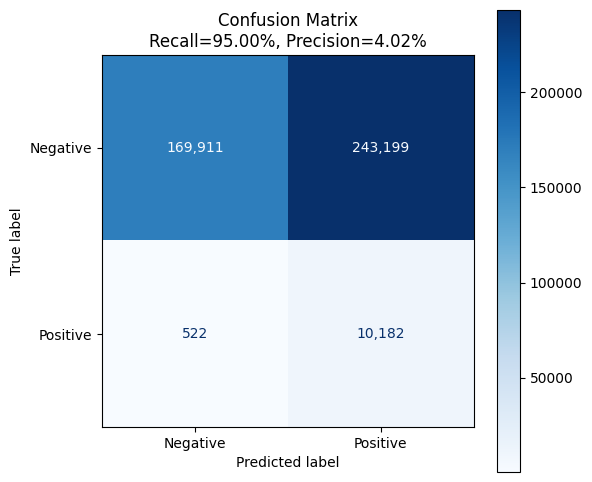

In [55]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test_enc, y_pred_95)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap="Blues", ax=ax,values_format=',d')

plt.title(
    f"Confusion Matrix\nRecall={0.95:.2%}, Precision={0.0402:.2%}"
)
plt.show()

In [71]:
for target in [0.90, 0.95]:
    print(f"\nTarget Recall: {target:.0%}")
    print(f"Actual Recall: {operating_points[target]['recall']:.4f}")
    print(f"Precision: {operating_points[target]['precision']:.4f}")
    print(f"Threshold: {operating_points[target]['threshold']:.6f}")


Target Recall: 90%
Actual Recall: 0.9000
Precision: 0.0491
Threshold: 0.011547

Target Recall: 95%
Actual Recall: 0.9500
Precision: 0.0405
Threshold: 0.006979


In [72]:
#What is the positivity rate in the test set?
positivity_rate = y_test_enc.mean()

print(f"Test positivity rate: {positivity_rate:.4%}")

Test positivity rate: 2.5256%


In [74]:
#what share of all tests would we have to do in order to capture 90% or 95% of all positives?

for target in [0.90, 0.95]:

    valid_idx = np.where(recalls >= target)[0]
    best_idx = valid_idx[np.argmax(precisions[valid_idx])]

    threshold = thresholds[min(best_idx, len(thresholds)-1)]

    y_pred = (
        best_model.predict_proba(X_test_enc)[:,1]
        >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test_enc,
        y_pred
    ).ravel()

    pct_tested = (tp + fp) / len(y_test_enc)

    print(f"\nTarget Recall: {target:.0%}")
    print(f"Actual Recall: {tp/(tp+fn):.2%}")
    print(f"Precision: {tp/(tp+fp):.2%}")
    print(f"Population Tested: {pct_tested:.2%}")


Target Recall: 90%
Actual Recall: 89.05%
Precision: 5.06%
Population Tested: 44.43%

Target Recall: 95%
Actual Recall: 94.23%
Precision: 4.19%
Population Tested: 56.80%


In [75]:
#Feature importance
importance_df = pd.DataFrame({
    "feature": encoder.get_feature_names_out(),
    "importance": best_model.feature_importances_
})

# Remove prefixes such as categorical__
importance_df["feature"] = (
    importance_df["feature"]
    .str.replace("categorical__", "", regex=False)
)

# Convert to percentages
importance_df["importance_pct"] = (
    importance_df["importance"] /
    importance_df["importance"].sum()
) * 100

importance_df = (
    importance_df
    .sort_values("importance_pct", ascending=False)
    .reset_index(drop=True)
)

importance_df[["feature", "importance_pct"]].head(20)

,feature,importance_pct
0,PartnerHIVStatus_NEGATIVE,5.759607
1,ScreenedTB_nan,5.529317
2,TestedHIVBefore_nan,5.494388
3,TBStatus_PRESUMED,5.413186
4,PartnerHIVStatus_POSITIVE,4.740553
5,PatientDisabled_NO,4.487058
6,CurrentlyOnPrep_YES,4.100785
7,BreastfeedingMother_YES,3.576748
8,MaritalStatus_DIVORCED,2.878544
9,ReceivedServices_TB,2.466062


In [78]:
importance_df["base_feature"] = (
    importance_df["feature"]
    .str.replace(r"^(categorical__|remainder__)", "", regex=True)
    .str.split("_")
    .str[0]
)

feature_summary = (
    importance_df
    .groupby("base_feature")["importance_pct"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

feature_summary.head(20)

,base_feature,importance_pct
0,PartnerHIVStatus,12.44
1,MaritalStatus,7.84
2,TBStatus,7.67
3,TestedHIVBefore,7.07
4,ScreenedTB,6.29
5,BreastfeedingMother,5.21
6,CurrentlyOnPrep,4.90
7,ReceivedServices,4.78
8,PatientDisabled,4.49
9,dayofweek,3.43
